In [4]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os

folders = os.listdir("/content/drive/MyDrive")

for folder in folders:
    if "SkillMe" in folder:
        print("Folder Name:", repr(folder))

Folder Name: 'SkillMe_Projects '


In [6]:
import os

project_path = "/content/drive/MyDrive/SkillMe_Projects "

print(os.path.exists(project_path))

os.chdir(project_path)

print("Project Folder Connected Successfully!")
print(os.getcwd())

True
Project Folder Connected Successfully!
/content/drive/MyDrive/SkillMe_Projects 


In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

In [8]:
digits = load_digits()

print("Dataset loaded successfully!")
print("Images Shape:", digits.images.shape)
print("Data Shape:", digits.data.shape)
print("Target Shape:", digits.target.shape)

Dataset loaded successfully!
Images Shape: (1797, 8, 8)
Data Shape: (1797, 64)
Target Shape: (1797,)


In [9]:
print("First 10 Labels:")
print(digits.target[:10])

First 10 Labels:
[0 1 2 3 4 5 6 7 8 9]


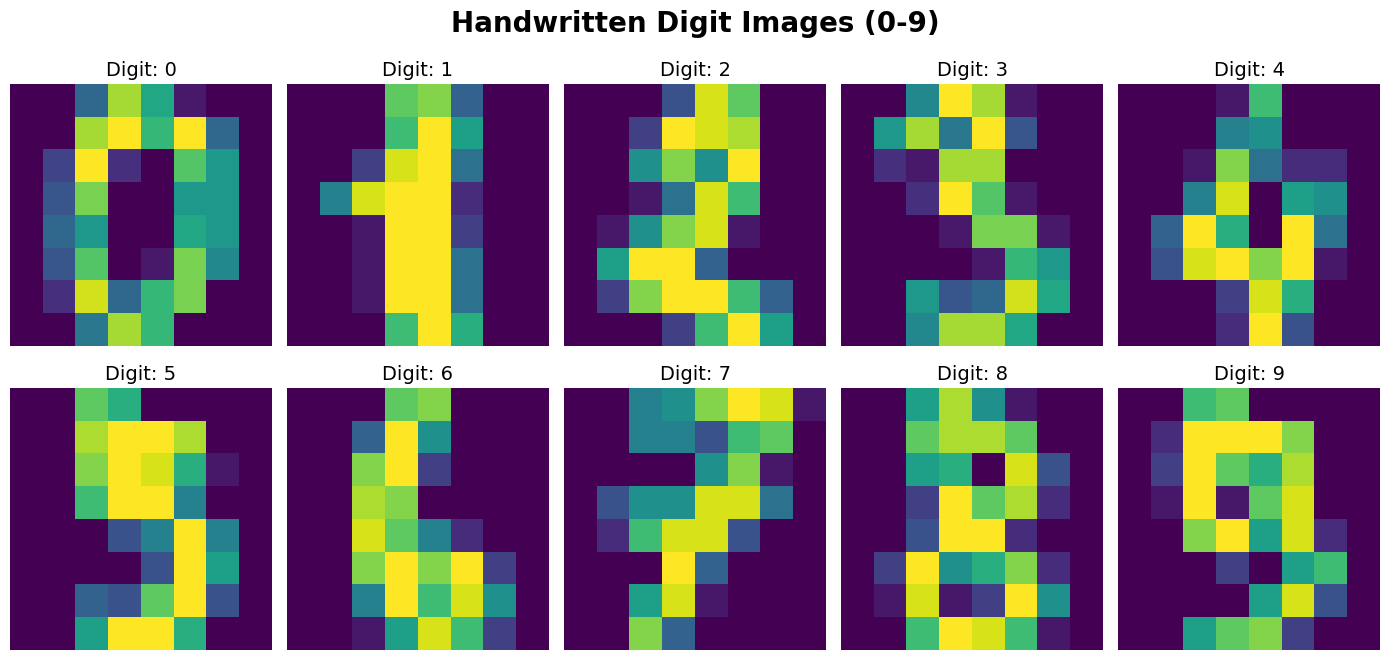

In [10]:
plt.figure(figsize=(14, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(digits.images[i], cmap='viridis')

    plt.title(f"Digit: {digits.target[i]}", fontsize=14)
    plt.axis('off')

plt.suptitle("Handwritten Digit Images (0-9)",
             fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

# Features (X) and Labels (y)
X = digits.data
y = digits.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (1437, 64)
Testing Data Shape: (360, 64)
Training Labels Shape: (1437,)
Testing Labels Shape: (360,)


In [12]:
from sklearn.neighbors import KNeighborsClassifier

In [13]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=3)

# Train the model
knn.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [14]:
# Predict test data
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = knn.score(X_test, y_test)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.33333333333333 %


In [15]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9]

results = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    results.append(accuracy * 100)

    print(f"K = {k}, Accuracy = {accuracy * 100:.2f}%")

K = 1, Accuracy = 97.78%
K = 3, Accuracy = 98.33%
K = 5, Accuracy = 98.61%
K = 9, Accuracy = 98.06%


In [16]:
import pandas as pd

comparison = pd.DataFrame({
    'K Value': k_values,
    'Accuracy (%)': results
})

print(comparison)

   K Value  Accuracy (%)
0        1     97.777778
1        3     98.333333
2        5     98.611111
3        9     98.055556


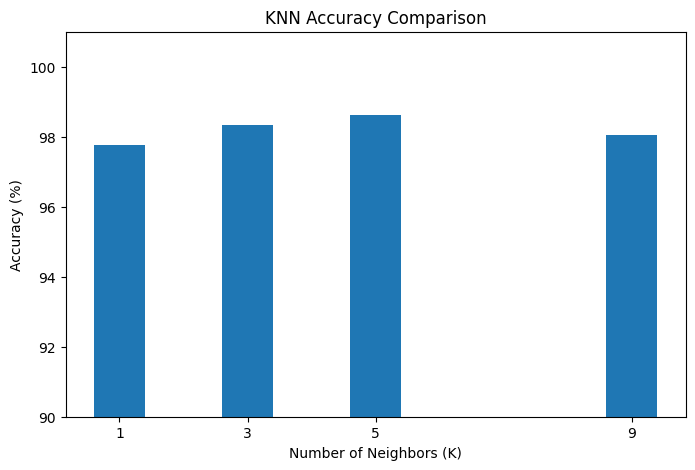

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(k_values, results)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy (%)")

plt.title("KNN Accuracy Comparison")

plt.xticks(k_values)
plt.ylim(90, 101)

plt.show()

In [18]:
# Create best KNN model
best_model = KNeighborsClassifier(n_neighbors=5)

# Train model
best_model.fit(X_train, y_train)

# Predict test images
y_pred = best_model.predict(X_test)

print("Best KNN Model Trained Successfully!")

Best KNN Model Trained Successfully!


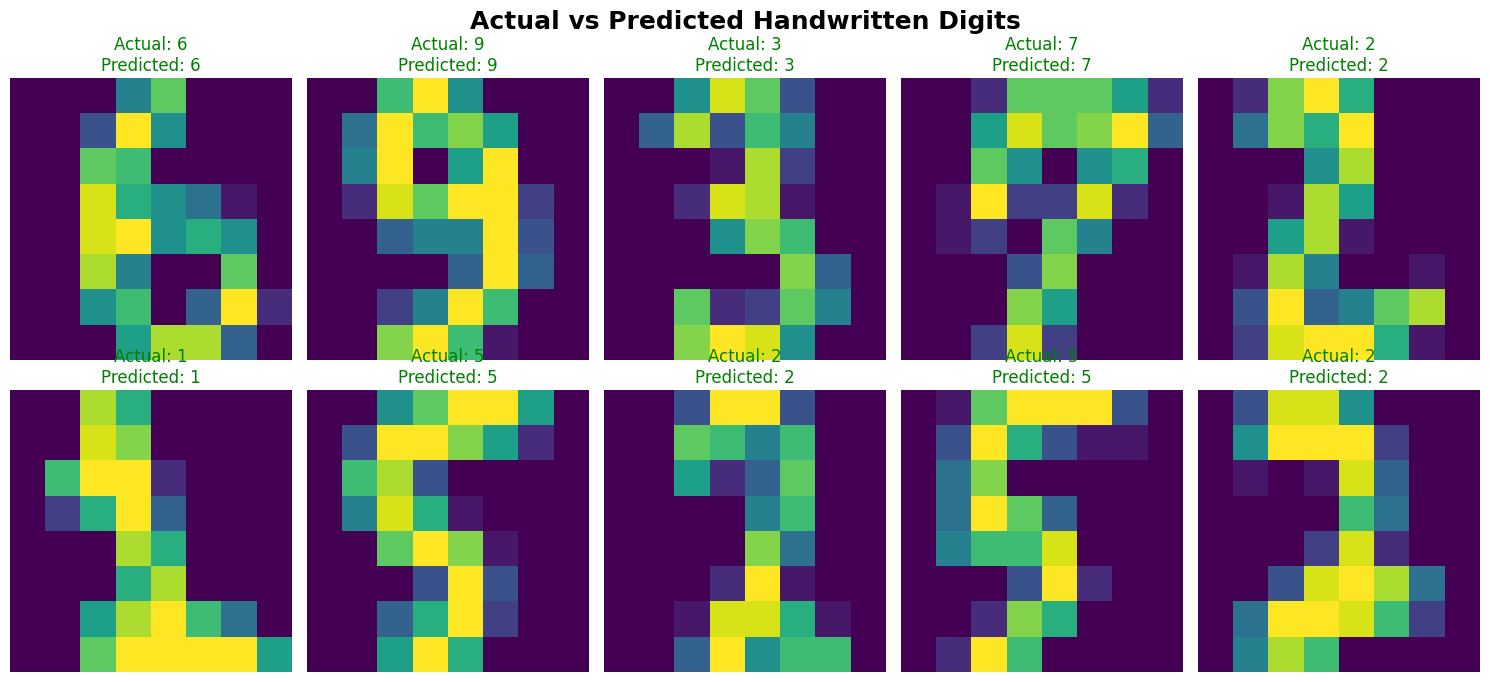

In [19]:
plt.figure(figsize=(15, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(8, 8)

    plt.imshow(image, cmap='viridis')

    actual = y_test[i]
    predicted = y_pred[i]

    if actual == predicted:
        color = 'green'
    else:
        color = 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=12
    )

    plt.axis('off')

plt.suptitle(
    "Actual vs Predicted Handwritten Digits",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate final accuracy
final_accuracy = accuracy_score(y_test, y_pred)

print("Final Model Accuracy:", round(final_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Model Accuracy: 98.61 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       0.98      1.00      0.99        46
           5       0.98      0.96      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       1.00      1.00      1.00        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [21]:
readme_content = """
# Handwritten Digit Classifier

## Project Overview
This project identifies handwritten digits (0-9)
using Machine Learning and the K-Nearest Neighbors
(KNN) algorithm.

## Dataset
- Dataset: Scikit-learn Digits Dataset
- Total Images: 1797
- Image Size: 8x8 pixels
- Classes: 0 to 9

## Technologies Used
- Python
- NumPy
- Matplotlib
- Pandas
- Scikit-learn
- Google Colab

## Machine Learning Algorithm
K-Nearest Neighbors (KNN)

## Train-Test Split
- Training Data: 80%
- Testing Data: 20%

## K Value Comparison

| K Value | Accuracy |
|---------|----------|
| 1 | 97.78% |
| 3 | 98.33% |
| 5 | 98.61% |
| 9 | 98.06% |

## Best Model
KNN with K = 5

## Final Accuracy
98.61%

## Conclusion
The model successfully classifies handwritten
digits with 98.61% test accuracy.
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [22]:
from google.colab import files

files.download('/content/drive/MyDrive/SkillMe_Projects /Handwritten_Digit_Classifier.ipynb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download('/content/drive/MyDrive/SkillMe_Projects /README.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [25]:
# Define 4 Machine Learning Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True),
    "Random Forest": RandomForestClassifier(random_state=42)
}

print("4 Models Created Successfully!")

4 Models Created Successfully!


In [26]:
# Compare Models using 5-Fold Cross Validation

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    results.append({
        "Model": name,
        "Accuracy": scores.mean() * 100
    })

    print(name)
    print("Cross Validation Accuracy:", scores.mean() * 100)
    print("--------------------------------")

results_df = pd.DataFrame(results)

print(results_df)

Logistic Regression
Cross Validation Accuracy: 95.33633372048004
--------------------------------
KNN
Cross Validation Accuracy: 98.32921989934185
--------------------------------
SVM
Cross Validation Accuracy: 98.60820751064654
--------------------------------
Random Forest
Cross Validation Accuracy: 97.35554587688733
--------------------------------
                 Model   Accuracy
0  Logistic Regression  95.336334
1                  KNN  98.329220
2                  SVM  98.608208
3        Random Forest  97.355546


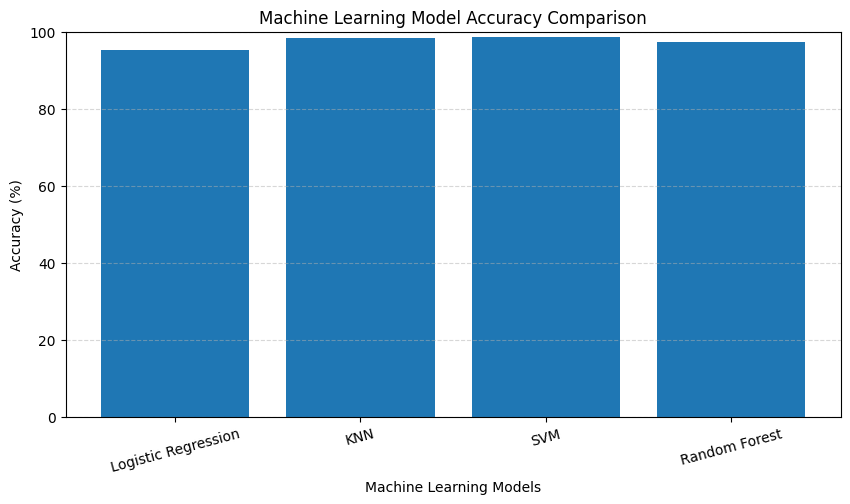

In [27]:
# Model Accuracy Comparison

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM Pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

# Train the model
svm_pipeline.fit(X_train, y_train)

# Make predictions
y_pred_scaled = svm_pipeline.predict(X_test)

# Calculate accuracy
scaled_accuracy = accuracy_score(y_test, y_pred_scaled)

print("Scaled SVM Accuracy:", scaled_accuracy * 100, "%")

Scaled SVM Accuracy: 98.05555555555556 %


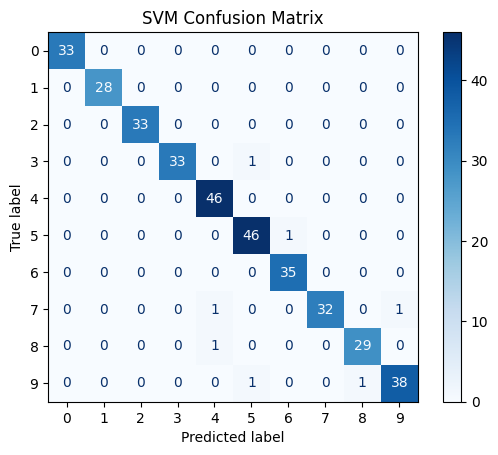

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Display Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    svm_pipeline,
    X_test,
    y_test,
    cmap='Blues',
    values_format='d'
)

plt.title("SVM Confusion Matrix")
plt.show()

Total Misclassified Images: 7


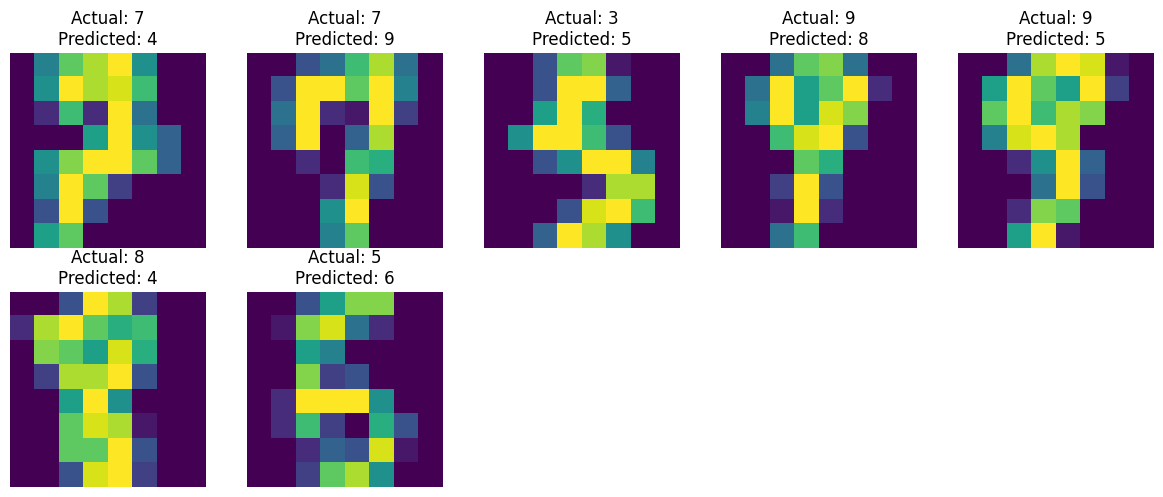

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrect predictions
misclassified = np.where(y_pred_scaled != y_test)[0]

print("Total Misclassified Images:", len(misclassified))

# Display up to 10 incorrect images
plt.figure(figsize=(12, 5))

for i, index in enumerate(misclassified[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index].reshape(8, 8), cmap='viridis')

    plt.title(
        f"Actual: {y_test.iloc[index] if hasattr(y_test, 'iloc') else y_test[index]}\n"
        f"Predicted: {y_pred_scaled[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [31]:
from sklearn.datasets import fetch_openml

# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

# Separate images and labels
X_mnist = mnist.data
y_mnist = mnist.target.astype(int)

print("MNIST Dataset Shape:", X_mnist.shape)
print("MNIST Labels Shape:", y_mnist.shape)

MNIST Dataset Shape: (70000, 784)
MNIST Labels Shape: (70000,)


In [32]:
X_mnist = X_mnist / 255.0

print("Normalized Pixel Values:")
print("Minimum:", X_mnist.min())
print("Maximum:", X_mnist.max())

Normalized Pixel Values:
Minimum: 0.0
Maximum: 1.0


In [33]:
from sklearn.model_selection import train_test_split

X_subset, _, y_subset, _ = train_test_split(
    X_mnist,
    y_mnist,
    train_size=10000,
    random_state=42,
    stratify=y_mnist
)

# Split into training and testing data
X_mnist_train, X_mnist_test, y_mnist_train, y_mnist_test = train_test_split(
    X_subset,
    y_subset,
    test_size=0.2,
    random_state=42,
    stratify=y_subset
)

print("Training Data:", X_mnist_train.shape)
print("Testing Data:", X_mnist_test.shape)

Training Data: (8000, 784)
Testing Data: (2000, 784)


In [34]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM model
mnist_model = SVC(kernel='rbf')

# Train model
mnist_model.fit(X_mnist_train, y_mnist_train)

# Make predictions
mnist_predictions = mnist_model.predict(X_mnist_test)

# Calculate accuracy
mnist_accuracy = accuracy_score(
    y_mnist_test,
    mnist_predictions
)

print("MNIST Test Accuracy:", mnist_accuracy * 100, "%")

MNIST Test Accuracy: 95.7 %


In [35]:
import joblib
import os

# Save model in Google Drive
save_path = "/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib"

joblib.dump(mnist_model, save_path)

print("Model saved successfully!")
print("File location:", save_path)

Model saved successfully!
File location: /content/drive/MyDrive/SkillMe_Projects /digit_model.joblib


In [36]:
import joblib

# Load saved model
loaded_model = joblib.load(save_path)

# Make predictions
predictions = loaded_model.predict(X_mnist_test[:5])

print("Predictions:", predictions)
print("Actual Labels:", y_mnist_test[:5])

Predictions: [8 2 1 2 9]
Actual Labels: [8 2 1 2 9]


In [37]:
from google.colab import files

files.download('/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:

!pip install gradio joblib numpy pillow scikit-learn


In [39]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:

import os
import glob

model_files = glob.glob(
    "/content/drive/MyDrive/**/digit_model.joblib",
    recursive=True
)

print("Model files found:", model_files)


Model files found: ['/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib']


In [41]:

import joblib

model_path = model_files[0]

digit_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(digit_model))
print("Probability support:", hasattr(digit_model, "predict_proba"))


Model loaded successfully!
Model type: <class 'sklearn.svm._classes.SVC'>
Probability support: False


In [42]:
from sklearn.svm import SVC

model = SVC(kernel='rbf')
model.fit(X_train, y_train)

SVC()

In [43]:
model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

In [44]:
import joblib

model_path = '/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib'

joblib.dump(model, model_path)

print("Updated model saved successfully!")

Updated model saved successfully!


In [45]:
digit_model = joblib.load(model_path)

print("Model:", type(digit_model))
print("Probability support:", digit_model.predict_proba is not None)

Model: <class 'sklearn.svm._classes.SVC'>
Probability support: True


In [46]:

import numpy as np
from PIL import Image, ImageOps

print("Libraries imported successfully!")


Libraries imported successfully!


In [47]:

def preprocess_image(image):

    # Convert image to grayscale
    image = image.convert("L")

    # Resize image to 28x28
    image = image.resize((28, 28))

    # Convert image into NumPy array
    image_array = np.array(image)

    # Normalize pixel values
    image_array = image_array / 255.0

    # Flatten image into 784 features
    image_array = image_array.reshape(1, 784)

    return image_array


In [48]:

# Create a sample blank image
sample_image = Image.new("L", (280, 280), color=0)

processed_image = preprocess_image(sample_image)

print("Original image size:", sample_image.size)
print("Processed image shape:", processed_image.shape)
print("Minimum pixel value:", processed_image.min())
print("Maximum pixel value:", processed_image.max())


Original image size: (280, 280)
Processed image shape: (1, 784)
Minimum pixel value: 0.0
Maximum pixel value: 0.0


In [49]:

from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


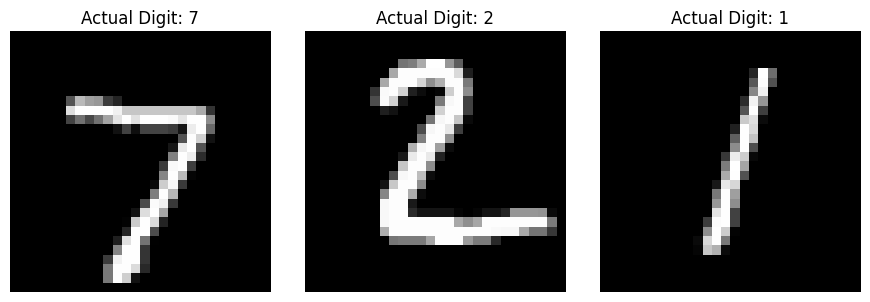

In [50]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"Actual Digit: {y_test[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [51]:

for i in range(3):

    image = Image.fromarray(X_test[i])

    processed = preprocess_image(image)

    print(f"Image {i+1}")
    print("Actual digit:", y_test[i])
    print("Processed shape:", processed.shape)
    print("Min value:", processed.min())
    print("Max value:", processed.max())
    print("-" * 30)


Image 1
Actual digit: 7
Processed shape: (1, 784)
Min value: 0.0
Max value: 1.0
------------------------------
Image 2
Actual digit: 2
Processed shape: (1, 784)
Min value: 0.0
Max value: 1.0
------------------------------
Image 3
Actual digit: 1
Processed shape: (1, 784)
Min value: 0.0
Max value: 1.0
------------------------------


In [52]:

# Select 3 test images
X_sample = X_test[:3]
y_sample = y_test[:3]

# Normalize and flatten images
X_sample_processed = X_sample.reshape(3, 784).astype("float32") / 255.0

print("Input shape:", X_sample_processed.shape)


Input shape: (3, 784)


In [53]:

from sklearn.svm import SVC
import joblib

# Create SVM model with probability support
mnist_model = SVC(
    kernel='rbf',
    probability=True
)

# Train using your original Week 2 training data
mnist_model.fit(X_mnist_train, y_mnist_train)

print("Model training completed!")


Model training completed!


In [54]:

model_path = '/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib'

joblib.dump(mnist_model, model_path)

print("Updated model saved successfully!")


Updated model saved successfully!


In [55]:

digit_model = joblib.load(model_path)

print("Model loaded:", type(digit_model))
print("Is model trained:", hasattr(digit_model, "classes_"))
print("Probability support:", digit_model.probability)


Model loaded: <class 'sklearn.svm._classes.SVC'>
Is model trained: True
Probability support: True


In [56]:
predictions = digit_model.predict(X_sample_processed)

for i in range(3):
    print("Actual:", y_sample[i])
    print("Predicted:", predictions[i])
    print("Correct:", predictions[i] == y_sample[i])
    print("-" * 30)

Actual: 7
Predicted: 7
Correct: True
------------------------------
Actual: 2
Predicted: 2
Correct: True
------------------------------
Actual: 1
Predicted: 1
Correct: True
------------------------------


In [57]:

import numpy as np

probabilities = digit_model.predict_proba(X_sample_processed)

for i in range(3):

    top_3 = np.argsort(probabilities[i])[::-1][:3]

    print(f"\nActual Digit: {y_sample[i]}")

    for digit in top_3:
        confidence = probabilities[i][digit] * 100
        print(f"Digit {digit}: {confidence:.2f}%")



Actual Digit: 7
Digit 7: 99.84%
Digit 3: 0.07%
Digit 2: 0.04%

Actual Digit: 2
Digit 2: 99.50%
Digit 3: 0.18%
Digit 0: 0.11%

Actual Digit: 1
Digit 1: 98.95%
Digit 8: 0.26%
Digit 2: 0.24%


In [58]:

!pip install -U gradio


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 37.1 MB/s  0:00:00
  Attempting uninstall: gradio
    Found existing installation: gradio 6.31.0
    Uninstalling gradio-6.31.0:
      Successfully uninstalled gradio-6.31.0


In [59]:

import gradio as gr

print("Gradio version:", gr.__version__)


Gradio version: 6.32.0


In [60]:
probabilities = digit_model.predict_proba(X_sample_processed)

for i in range(3):
    top_3 = np.argsort(probabilities[i])[::-1][:3]

    print(f"\nActual Digit: {y_sample[i]}")

    for digit in top_3:
        print(
            f"Digit {digit}: "
            f"{probabilities[i][digit] * 100:.2f}%"
        )


Actual Digit: 7
Digit 7: 99.84%
Digit 3: 0.07%
Digit 2: 0.04%

Actual Digit: 2
Digit 2: 99.50%
Digit 3: 0.18%
Digit 0: 0.11%

Actual Digit: 1
Digit 1: 98.95%
Digit 8: 0.26%
Digit 2: 0.24%


In [63]:
print("X_test shape:", X_test.shape)
print("X_train shape:", X_train.shape)

X_test shape: (10000, 28, 28)
X_train shape: (60000, 28, 28)


In [75]:
import gradio as gr
import numpy as np
import joblib

from PIL import Image, ImageOps


# Load trained model
MODEL_PATH = "/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib"

model = joblib.load(MODEL_PATH)

print("VisionAI model loaded successfully!")


# Convert input into PIL image
def convert_to_pil(image):

    if image is None:
        return None

    if isinstance(image, dict):
        image = image.get("composite")

    if image is None:
        return None

    if isinstance(image, np.ndarray):

        if image.size == 0:
            return None

        if image.dtype != np.uint8:

            image = np.nan_to_num(image)

            if image.max() <= 1:
                image = image * 255

            image = np.clip(image, 0, 255).astype(np.uint8)

        image = Image.fromarray(image)

    return image


# Improved preprocessing
def preprocess_image(image):

    image = image.convert("RGB")
    image = ImageOps.grayscale(image)

    arr = np.array(image)

    # Detect background using corner pixels
    corners = [
        arr[0, 0],
        arr[0, -1],
        arr[-1, 0],
        arr[-1, -1]
    ]

    background = np.mean(corners)

    # Convert white background to black
    if background > 127:
        image = ImageOps.invert(image)

    arr = np.array(image)

    # Detect digit
    mask = arr > 30

    if not np.any(mask):
        raise ValueError("Please draw a digit first!")

    # Crop extra blank space
    rows = np.where(np.any(mask, axis=1))[0]
    cols = np.where(np.any(mask, axis=0))[0]

    top = rows.min()
    bottom = rows.max() + 1
    left = cols.min()
    right = cols.max() + 1

    image = image.crop((left, top, right, bottom))

    # Resize while maintaining aspect ratio
    image.thumbnail((20, 20))

    # Create 28x28 black canvas
    canvas = Image.new("L", (28, 28), 0)

    # Center digit
    x = (28 - image.width) // 2
    y = (28 - image.height) // 2

    canvas.paste(image, (x, y))

    # Normalize
    arr = np.array(canvas).astype("float32") / 255.0

    return arr.reshape(1, 784)


# Prediction function
def predict_digit(sketch, uploaded_image):

    try:

        image = convert_to_pil(uploaded_image)

        if image is None:
            image = convert_to_pil(sketch)

        if image is None:
            return {}, "Please draw or upload a digit."

        processed = preprocess_image(image)

        probabilities = model.predict_proba(processed)[0]

        top_3 = np.argsort(probabilities)[::-1][:3]

        results = {
            str(int(digit)): float(probabilities[digit])
            for digit in top_3
        }

        best_digit = int(top_3[0])

        confidence = probabilities[best_digit] * 100

        message = (
            f"Prediction successful! "
            f"Digit: {best_digit} | "
            f"Confidence: {confidence:.2f}%"
        )

        return results, message

    except ValueError as error:

        return {}, str(error)

    except Exception as error:

        print("Error:", error)

        return {}, "Unable to process image. Please try again."


# Gradio interface
with gr.Blocks(title="VisionAI - Digit Recognition") as demo:

    gr.Markdown(
        """
        # VisionAI - Handwritten Digit Recognition

        Draw a digit from 0 to 9 or upload a handwritten image.
        Our machine learning model will predict your digit.
        """
    )

    with gr.Row():

        with gr.Column():

            sketch = gr.Sketchpad(
                label="Draw Your Digit",
                type="numpy",
                height=300,
                width=300
            )

            upload = gr.Image(
                type="pil",
                label="Upload Handwritten Digit"
            )

            predict_button = gr.Button(
                "Predict Digit",
                variant="primary"
            )

        with gr.Column():

            output = gr.Label(
                num_top_classes=3,
                label="Top 3 Predictions"
            )

            status = gr.Textbox(
                label="Prediction Status",
                interactive=False
            )

    predict_button.click(
        fn=predict_digit,
        inputs=[sketch, upload],
        outputs=[output, status]
    )

    gr.Markdown(
        "### Technology: Python | SVM | MNIST | Gradio"
    )


if __name__ == "__main__":

    demo.launch(share=True)

VisionAI model loaded successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://153d40f0c7cc7146be.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [76]:
!pip freeze > requirements.txt


In [64]:
# Flatten test images
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Normalize pixel values
X_test_flat = X_test_flat.astype("float32") / 255.0

print("Original Shape:", X_test.shape)
print("Processed Shape:", X_test_flat.shape)

Original Shape: (10000, 28, 28)
Processed Shape: (10000, 784)


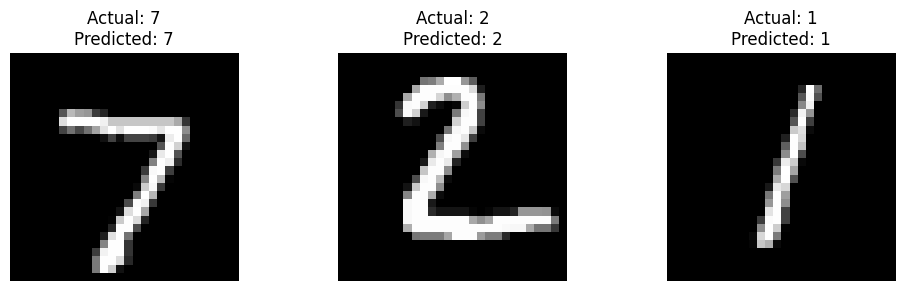

In [68]:
import matplotlib.pyplot as plt

# Display 3 test images
plt.figure(figsize=(10, 3))

for i in range(3):
    plt.subplot(1, 3, i + 1)

    plt.imshow(X_test[i], cmap="gray")

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [69]:
y_pred = digit_model.predict(X_test_flat)

In [70]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy * 100, "%")

Test Accuracy: 96.47 %


<Figure size 1000x800 with 0 Axes>

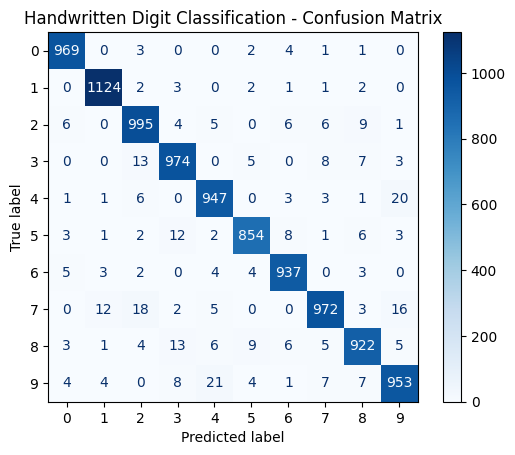

In [71]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Handwritten Digit Classification - Confusion Matrix")
plt.show()

In [72]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)

print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.95      0.96      0.96      1032
           3       0.96      0.96      0.96      1010
           4       0.96      0.96      0.96       982
           5       0.97      0.96      0.96       892
           6       0.97      0.98      0.97       958
           7       0.97      0.95      0.96      1028
           8       0.96      0.95      0.95       974
           9       0.95      0.94      0.95      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000

